# Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name:**  
**Title of the experiment:**  
**Starting date:**  
**Expected enddate:**  
**Partner:**  
**Goal of the experiment:**  
**Research question:**  
**Expectations or Hypothesis:**  
**Desired accuracy:**  




In [1]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 

# Preparation
 


**Assignments:**  

**Method:**  
**Theory:**  
**Independent variable:**  
**Dependent variable:**  
**Controlled variablen:**  
**Measurement instruments \& Settings:**  
**Procedure:**  
**Setup(drawing or picture):**  
**Notes:**  
**About accuracy:**  


# Execution

### weerstands metingen:

Accuracy± (% of Reading + % of Range)

| Range | Uncertainty at 23 ± 5 °C | Temperature coefficient (outside 23 ± 5 °C) |
|---|---|---|
| 200 Ω | ±(0.030 + 0.005) | ±(0.0030 + 0.0006) per °C |
| 2 kΩ | ±(0.020 + 0.003) | ±(0.0030 + 0.0005) per °C |
| 20 kΩ | ±(0.020 + 0.003) | ±(0.0030 + 0.0005) per °C |
Reference:
https://siglentna.com/wp-content/uploads/dlm_uploads/2023/04/SDM3055_Datasheet_E04A.pdf

R_1: 99927 ± 3  <!--2.59854-->

R_2: 468.26 ± 0.2  <!--0.15362-->

R_3: 100.34 ± 0.04  <!--100.34 ± 0.0401008-->

In [2]:
# Measurements: Explain the names of variables provide only raw data in np.arrays!
R_1=9.9927e3
R_2=468.26 
R_3=100.336 

U_1=np.array([0.042e-3,0.071e-3,0.153e-3,0.439e-3,1.1074e-3,2.643e-3,5.965e-3,
            12.567e-3,24.038e-3,41.210e-3,63.703e-3,90.445e-3,120.422e-3,152.635e-3,
            186.805e-3,0.22222,0.25868,0.29611,0.33403,0.37271,0.41180,0.45115,
            0.49100,0.53111,0.57136,0.65266,0.73476,0.81722,0.90029,0.98351,
            1.06735,1.15130,1.23554,1.31995,1.40457
            ])
U_bron=np.array([0.25,0.34,0.49,0.74,0.99,1.24,1.49,1.74,1.99,2.24,2.49,2.74,2.99,
                 3.24,3.49,3.74,3.99,4.24,4.49,4.74,4.99,5.24,5.49,5.74,5.99,6.49,
                 6.99,7.49,7.99,8.49,8.99,9.49,9.99,10.49,10.99
            ])

**Observations:**  
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**


Text(0.5, 0, 'Voltage Diode $(U)$')

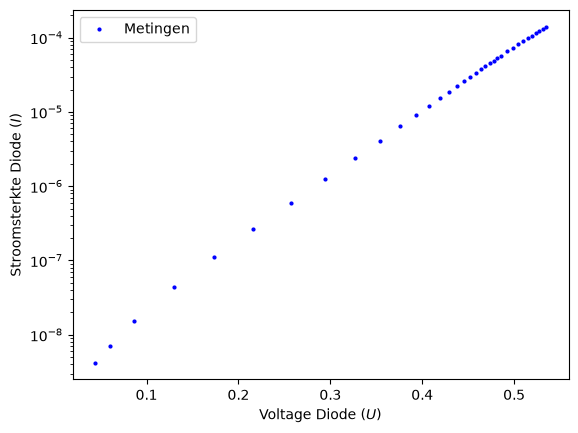

In [35]:
U_3=R_3/(R_2+R_3)*U_bron
U_diode=U_3-U_1
I_diode=U_1/R_1

plt.figure()
plt.yscale('log')
plt.plot(U_diode,I_diode,'b.',markersize=4,label='Metingen')
plt.legend()
plt.ylabel('Stroomsterkte Diode $(I)$')
plt.xlabel('Voltage Diode $(U)$')

In [30]:
#thoughts and shit dw abt this
I_0=?

def funcfit(U_diode,a):
    return I_0*(np.exp(a*diode)-1)
val,cov=curve_fit(funcfit,U_diode,I_diode,p0=())
plt.figure()
plt.plot(U_diode,funcfit(U_diode,*val),label='fit function')
plt.legend()
plt.ylabel('Stroomsterkte Diode $(I)$')
plt.xlabel('Voltage Diode $(U)$')
temp_val=val
temp_val_unc=np.sqrt(np.diag(cov))

q=-1.602176634e-19
n=2
n_unc=0.1
T= 20+273.15 #temp in kelvin
T_unc=1 #arbitrair

k_B=-q/(n*T*b)
k_B_unc=k_B*np.sqrt((n_unc/n)**2+(T_unc/T)**2+(temp_val/temp_val_unc)**2)

SyntaxError: invalid syntax (314511550.py, line 2)

I_0 = 3.58e-09 ± 2e-11 A)
(just to test) a  = 19.94 ± 0.02 1/V
k_B = 1.362e-23 ± 7e-25 J/K   (literatuur: 1.381e-23)


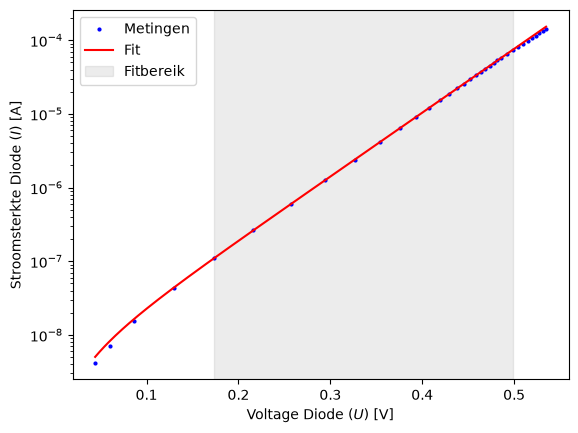

N_sigma has the value: 0.2738640961135512
Conclusion: the values are in good agreement.


In [43]:
q  = 1.602176634e-19     # C, sign is anders dan voorbereiding, schilt een min factor in de berekening
T  = 295.0               # K, kamertemp, assumed
T_unc = 1.0              # K, onzekerheid in T, assumed
n  = 2.0                 # aangenomen idealiteitsfactor silicum uit voorbereiding
n_unc = 0.1

# Verwerking
U_3 = R_3/(R_2+R_3)*U_bron
U_diode = U_3 - U_1
I_diode = U_1/R_1

# Fitbereik: weg van ruis (laag) en serieweerstand (hoog), zodat we alleen het lineare deel bekijken, waardoor we de constante kunnen berekenen
mask = (U_diode > 0.14) & (U_diode < 0.5)
U_diode_mask, I_diode_mask = U_diode[mask], I_diode[mask]

# model in log vorm, zodat alle decaden even zwaar meetellen
# vrije parameters: ln(I0) en a = q/(n kB T)
def model(U, lnI_0, a):
    return lnI_0 + np.log(np.exp(a*U) - 1) #ln is makkelijker met terug converten

val2, cov2 = curve_fit(model, U_diode_mask, np.log(I_diode_mask), p0=[np.log(1e-9), 20.0])
lnI_0, a = val2
lnI_0_unc, a_unc = np.sqrt(np.diag(cov2))
I_0 = np.exp(lnI_0)
I_0_unc=np.exp(lnI_0_unc)
I_0_unc=I_0-I_0/I_0_unc

# Boltzmann-constante
k_B  = q/(a*n*T)
k_B_unc = k_B*np.sqrt((a_unc/a)**2 + (n_unc/n)**2 + (T_unc/T)**2)

print(f"I_0 = {I_0:.2e} ± {I_0_unc:.0e} A)")
print(f"(just to test) a  = {a:.2f} ± {a_unc:.2f} 1/V")
print(f"k_B = {k_B:.3e} ± {k_B_unc:.0e} J/K   (literatuur: 1.381e-23)")

# quickie test voor strijdigheid
#print(k_B,'+/-',k_B_unc,k_B+k_B_unc)

# Plot
plt.figure()
plt.yscale('log')
plt.plot(U_diode, I_diode, 'b.', markersize=4, label='Metingen')
Ufit = np.linspace(min(U_diode),max(U_diode), 200)
plt.plot(Ufit, I_0*(np.exp(a*Ufit)-1), 'r-', label='Fit')
plt.axvspan(min(U_diode_mask), max(U_diode_mask), color='gray', alpha=0.15, label='Fitbereik')
plt.xlabel('Voltage Diode $(U)$ [V]')
plt.ylabel('Stroomsterkte Diode $(I)$ [A]')
plt.legend()
plt.show()

#strijdigheids analyse
delta_k_B=1.380649e-23-k_B
#boltzman referentie is gedefinieerd dus geen uncertainty combined
N_sigma=delta_k_B/k_B_unc
print('N_sigma has the value:',N_sigma)
if N_sigma < 1:
    print("Conclusion: the values are in good agreement.")

elif N_sigma < 2:
    print("Conclusion: the values are reasonably compatible.")

else:
    print("Conclusion: the experimental result is in conflict with the defined value.")

**Describing the pattern in the processed data:**  


**Notes:**  we waren vergeten de sperstroom te meten dus hebben dit gedaan met de curve fit in log vorm aangezien het dan gewoon een losse y-as-verplaatsende factor is. voor vervolg onderzoek zal dit moeten worden gemeten voor een betrouwbaarder resultaat. verder zit er een afwijking in onze boltzman constante dus zal de idealiteits factor moet worden nagekeken aangezien het mischien een systematische fout kan zijn in ons specifieke resistor bord.

# Discussion



# Conclusion

Fout in idealiteits factor? of meetfouten, iets moet de afwijkende boltzman constante uitleggen

# Additional notes, remarks, explanations, thoughts etc